In [2]:
# ДЗ 7
# Преоразовать существующий код для распознавания последовательности рукописных символов в текст.
# Написать генератор произвольной последовательности рукописных символов.

# ГЕНЕРАЦИЯ НАБОРА ДАННЫХ
# Сгенерировать набор текстовых строк из допустимых символов.
# Каждому набору поставить в соотвествие массив изоражений соответствующих символов.
# Добавить пробелы для разделения слов, символы пробелов не использовать во время классификации.

# КЛАССИФИКАЦИЯ (k ближайших соседей) (пример AIM practice 2)
# Часть символов оставить для обучения классификатора . Остальные  классифицировать
# по аналогии с примером mnist с прошлого занятия. Т.е. преобразовывать изображение в вектор.
# Выбрать оптимальный классификатор в зависимости от k- количество соседей.
# Метрика для измерения точности классификации, и выбора оптимального классификатора относительно параметра k - accuracy.

# РАСПОЗНАВАНИЕ
# заменить inf_net на последовательное применение следующих шагов:
# 1. генерация изображения с последовательностью символов
# 2. Выделение объектов оставляете как есть.
# 3. Примернить k-nn для решения задачи классификации. 
# 4. Вывести результат

In [6]:
import os
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# Параметры

In [7]:
path_to_folder = './data'
IMAGE_SIZE = 45
K_VALUES = [1, 3, 5, 7]
RANDOM_STATE = 42

def normalize_symbol_name(symbol: str) -> str:
    mapping = {'X': 'x', 'times': '*'}
    return mapping.get(symbol, symbol)

def get_available_symbols(data_path: str) -> list[str]:
    if not os.path.exists(data_path):
        return []
    return [
        name for name in sorted(os.listdir(data_path))
        if os.path.isdir(os.path.join(data_path, name)) and not name.startswith('.')
    ]

raw_symbols = get_available_symbols(path_to_folder)
print(f"Найденные папки-классы ({len(raw_symbols)}): {raw_symbols}")

Найденные папки-классы (21): ['(', ')', '+', ',', '-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'X', 'h', 't', 'times', 'w', 'y']


# Загрузка датасета

In [18]:
def load_dataset(data_path: str, img_size: int = IMAGE_SIZE, max_for_class: int = 50000):
    X, y = [], []
    class_names = []
    
    for class_idx, symbol in enumerate(raw_symbols):
        symbol_dir = os.path.join(data_path, symbol)
        files = os.listdir(symbol_dir)
        random.shuffle(files)
        files = files[:max_for_class]
        
        normalized_name = normalize_symbol_name(symbol)
        class_names.append(normalized_name)
        
        for file in files:
            img_path = os.path.join(symbol_dir, file)
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            if img is None:
                continue
            
            img = cv2.bitwise_not(img)
            img = cv2.resize(img, (img_size, img_size))
            
            X.append(img.flatten().astype(np.float32) / 255.0)
            y.append(class_idx)
            
    return np.array(X), np.array(y), class_names

X, y, class_names = load_dataset(path_to_folder)
print(f"X: {X.shape}, y: {y.shape}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, shuffle=True, stratify=y, random_state=RANDOM_STATE
)
print(f"Обучающая выборка: {len(X_train)}, Тестовая: {len(X_test)}")

X: (225291, 2025), y: (225291,)
Обучающая выборка: 202761, Тестовая: 22530


# Подбор параметра K и обучение

In [19]:
accuracies = []
for k in K_VALUES:
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn.fit(X_train, y_train)
    acc = accuracy_score(y_test, knn.predict(X_test))
    accuracies.append(acc)
    print(f"k = {k:2d} | точность = {acc:.4f}")

best_k = K_VALUES[int(np.argmax(accuracies))]
print(f"\nОптимальное k = {best_k}, точность = {max(accuracies):.4f}")

best_knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
best_knn.fit(X_train, y_train)

k =  1 | точность = 0.9941
k =  3 | точность = 0.9575
k =  5 | точность = 0.8053
k =  7 | точность = 0.7488

Оптимальное k = 1, точность = 0.9941


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",-1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](21,)","[ 0, 1, 2,...,18,19,20]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


# Генератор последовательностей

In [20]:
class HandwrittenSymbolsGenerator:
    def __init__(self, data_path: str, spacing: int = 20):
        self.data_path = data_path
        self.spacing = spacing
        self.symbols = get_available_symbols(data_path)

    def generate_sequence(self, length: int = 8):
        chosen_symbols = random.choices(self.symbols, k=length)
        normalized_seq = [normalize_symbol_name(s) for s in chosen_symbols]
        
        images = []
        for symbol_folder in chosen_symbols:
            symbol_dir = os.path.join(self.data_path, symbol_folder)
            files = os.listdir(symbol_dir)
            if not files:
                continue
            img_path = os.path.join(symbol_dir, random.choice(files))
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                images.append(cv2.bitwise_not(img))
                
        if not images:
            raise ValueError("Не удалось сгенерировать изображения для последовательности!")
            
        total_width = sum(img.shape[1] for img in images) + self.spacing * (len(images) - 1)
        max_height = max(img.shape[0] for img in images)
        
        sequence_img = np.zeros((max_height, total_width), dtype=np.uint8)
        x_offset = 0
        for img in images:
            h, w = img.shape
            sequence_img[0:h, x_offset:x_offset + w] = img
            x_offset += w + self.spacing
            
        padded_result = cv2.copyMakeBorder(sequence_img, 20, 20, 20, 20, cv2.BORDER_CONSTANT, value=0)
        return "".join(normalized_seq), padded_result

generator = HandwrittenSymbolsGenerator(path_to_folder)

# Сегментация и распознавание

In [23]:
def pad_to_size(img, target_size=(IMAGE_SIZE, IMAGE_SIZE)):
    h, w = img.shape
    target_h, target_w = target_size
    padded = np.zeros(target_size, dtype=np.uint8)
    y_start = (target_h - h) // 2
    x_start = (target_w - w) // 2
    padded[y_start:y_start+h, x_start:x_start+w] = img
    return padded

def recognize_sequence(expr, test_img):
    _, thresh = cv2.threshold(test_img, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    bboxes = []
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        if w * h > 30:
            bboxes.append((x, y, w, h))
            
    bboxes.sort(key=lambda b: b[0])
    
    recognized_chars = []
    vis_img = cv2.cvtColor(test_img, cv2.COLOR_GRAY2RGB)
    
    for (x, y, w, h) in bboxes:
        crop = test_img[y:y+h, x:x+w]
        
        side = max(w, h)
        pad_y = (side - h) // 2
        pad_x = (side - w) // 2
        roi_sq = cv2.copyMakeBorder(crop, pad_y, side - h - pad_y, pad_x, side - w - pad_x, cv2.BORDER_CONSTANT, value=0)
        roi_resized = cv2.resize(roi_sq, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_AREA)
        
        feat = roi_resized.flatten().astype(np.float32) / 255.0
        
        pred_idx = best_knn.predict([feat])[0]
        pred_char = class_names[pred_idx]
        recognized_chars.append(pred_char)
        
        cv2.rectangle(vis_img, (x, y), (x + w, y + h), (0, 0, 255), 1)
        cv2.putText(vis_img, pred_char, (x, max(y - 5, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)
        
    recognized_str = "".join(recognized_chars)
    return expr, recognized_str, vis_img

# Результат

Запуск тестирования на 100 сгенерированных последовательностях...



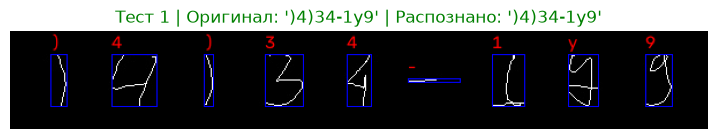

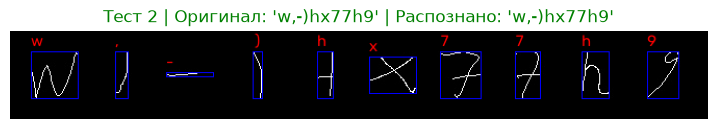

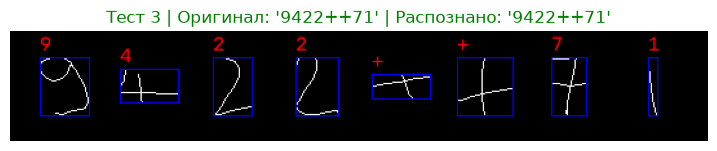

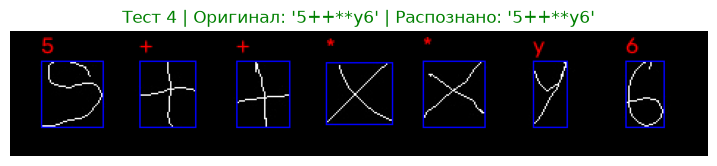

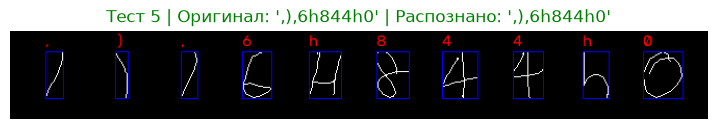

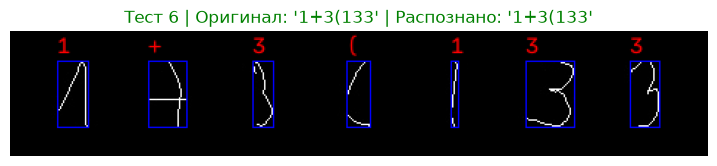

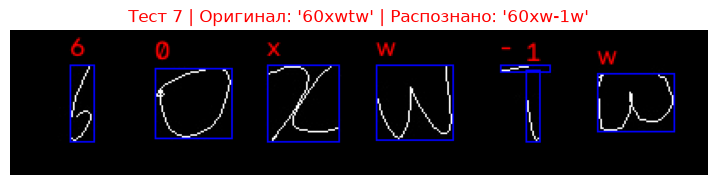

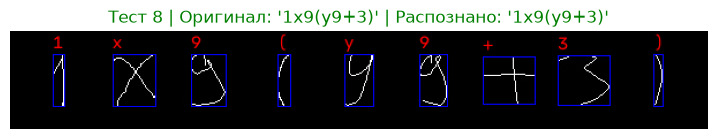

ИТОГОВЫЕ РЕЗУЛЬТАТЫ ТЕСТИРОВАНИЯ:
Проверено последовательностей: 100
Точных совпадений строк целиком: 60/100 (60.00%)
Посимвольная точность (Character Accuracy): 611/809 (75.53%)


In [24]:
def evaluate_on_sequences(num_tests=100, show_first_demos=3):
    correct_full_matches = 0
    total_symbols_checked = 0
    correct_symbols_checked = 0
    
    print(f"Запуск тестирования на {num_tests} сгенерированных последовательностях...\n")
    
    for i in range(num_tests):
        true_seq, test_img = generator.generate_sequence(length=random.randint(6, 10))
        expr, rec_seq, vis_img = recognize_sequence(true_seq, test_img)
        
        for t_char, r_char in zip(expr, rec_seq):
            total_symbols_checked += 1
            if t_char == r_char:
                correct_symbols_checked += 1
                
        is_exact_match = (expr == rec_seq)
        if is_exact_match:
            correct_full_matches += 1
            
        if i < show_first_demos:
            plt.figure(figsize=(9, 2))
            plt.imshow(vis_img)
            plt.axis('off')
            plt.title(f"Тест {i+1} | Оригинал: '{expr}' | Распознано: '{rec_seq}'", 
                      color='green' if is_exact_match else 'red')
            plt.show()

    full_match_acc = (correct_full_matches / num_tests) * 100
    symbol_acc = (correct_symbols_checked / total_symbols_checked) * 100
    
    print("=" * 50)
    print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ ТЕСТИРОВАНИЯ:")
    print("=" * 50)
    print(f"Проверено последовательностей: {num_tests}")
    print(f"Точных совпадений строк целиком: {correct_full_matches}/{num_tests} ({full_match_acc:.2f}%)")
    print(f"Посимвольная точность (Character Accuracy): {correct_symbols_checked}/{total_symbols_checked} ({symbol_acc:.2f}%)")
    print("=" * 50)

evaluate_on_sequences(num_tests=100, show_first_demos=8)